# Experiment 2 — Visualization of Data

**Aim:** Communicate data patterns using charts, histograms, scatter plots, and related visualizations.

**Libraries:** pandas, NumPy, Matplotlib, and Seaborn.

**Theory:** Histograms describe numeric distributions, bar charts compare categories, and scatter plots show relationships between numeric variables. Labels, units, scales, and legends must be clear.

**Dataset:** Iris flower dataset (local copy: `datasets/iris.csv`, from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/53/iris)): 150 flowers, 50 per species, 4 numeric measurements each.

## Procedure / Implementation
The following cells load the data, apply the stated method, produce outputs, and record observations.


In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

for candidate in [Path("datasets"), Path("../datasets")]:
    if candidate.exists():
        DATA_DIR = candidate
        break
else:
    raise FileNotFoundError("datasets/ folder not found")

for candidate in [Path("outputs"), Path("../outputs")]:
    if candidate.exists():
        OUTPUT_DIR = candidate
        break

FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load and display the dataset

In [2]:
df = pd.read_csv(DATA_DIR / "iris.csv")

print("Shape:", df.shape)
print("\nSpecies counts:")
print(df["species"].value_counts())
df.head()

Shape: (150, 5)

Species counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 2. Histogram of each flower measurement

Each histogram shows how one measurement is spread across all 150 flowers. Sepal width looks close to a normal curve, while petal length and petal width have two visible humps — the setosa flowers sit apart from the other two species.

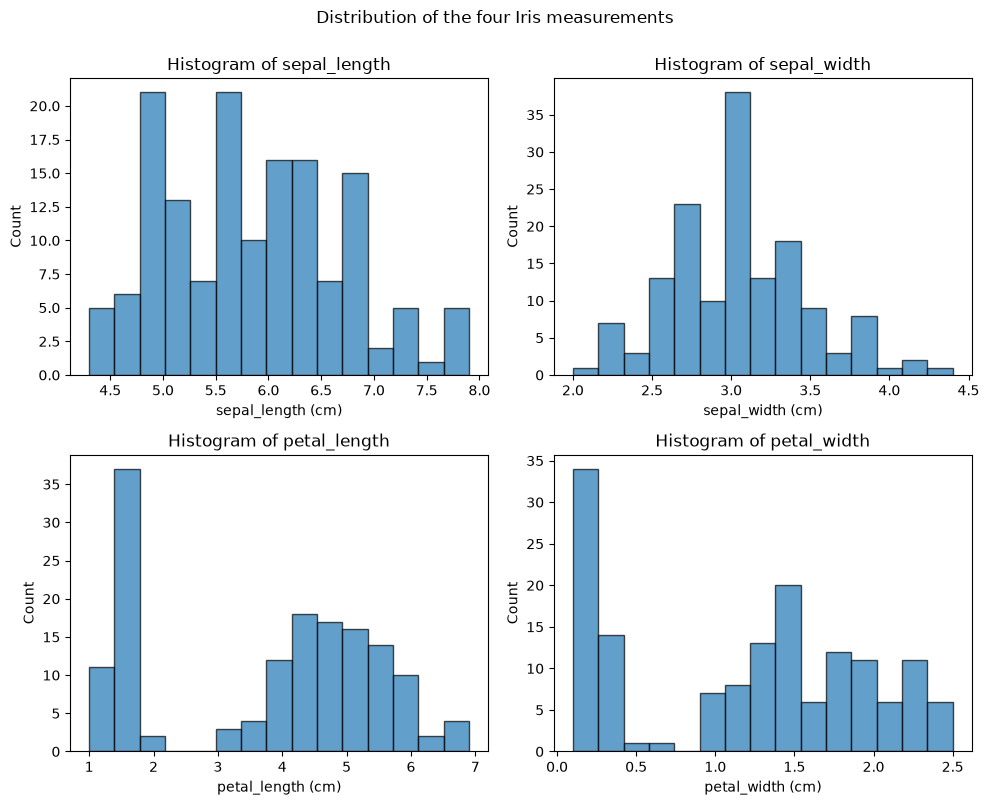

In [3]:
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, feat in zip(axes.ravel(), features):
    ax.hist(df[feat], bins=15, edgecolor="black", alpha=0.7)
    ax.set_title(f"Histogram of {feat}")
    ax.set_xlabel(feat + " (cm)")
    ax.set_ylabel("Count")

fig.suptitle("Distribution of the four Iris measurements", y=1.00)
plt.tight_layout()
plt.savefig(FIG_DIR / "exp02_histograms.png", dpi=150)
plt.show()

## 3. Scatter plot — petal length vs petal width, coloured by species

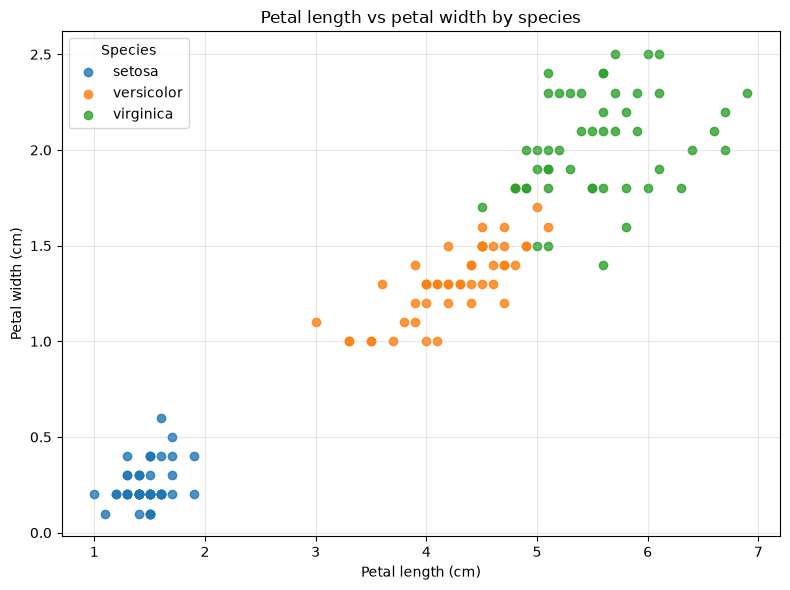

In [4]:
plt.figure(figsize=(8, 6))
for species, group in df.groupby("species"):
    plt.scatter(group["petal_length"], group["petal_width"], label=species, alpha=0.8)

plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Petal length vs petal width by species")
plt.legend(title="Species")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "exp02_petal_scatter.png", dpi=150)
plt.show()

## 4. Box plots — one per measurement, grouped by species

Box plots summarise the median, quartiles and outliers of each measurement within each species.

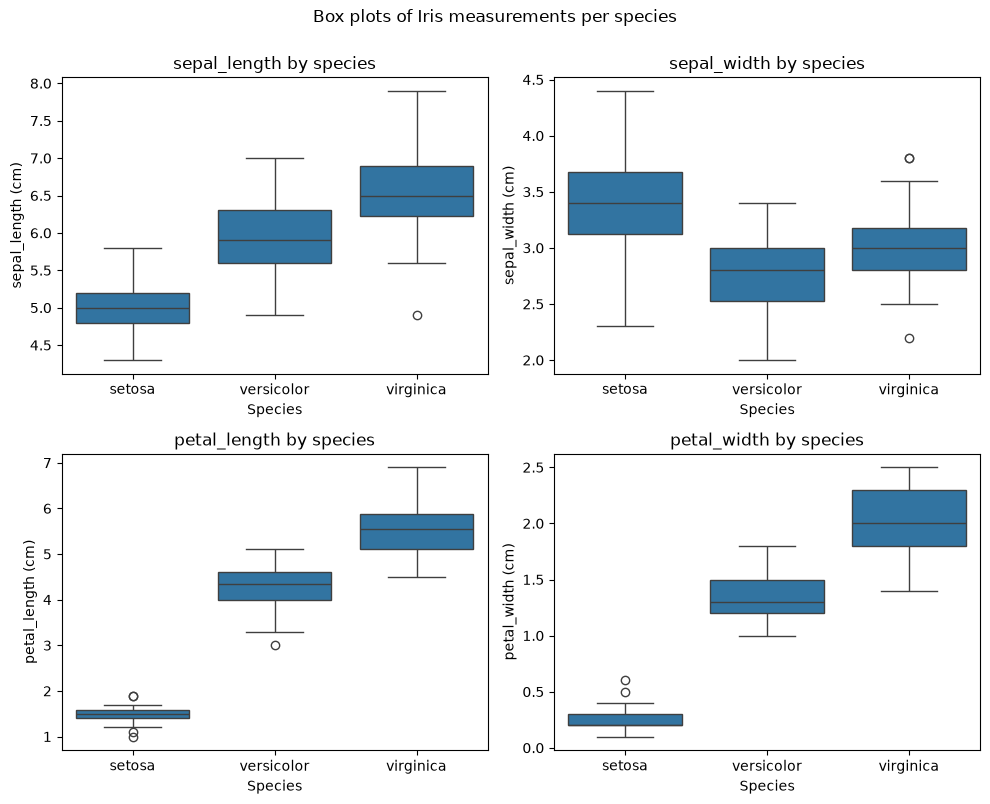

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, feat in zip(axes.ravel(), features):
    sns.boxplot(data=df, x="species", y=feat, ax=ax, order=sorted(df["species"].unique()))
    ax.set_title(f"{feat} by species")
    ax.set_xlabel("Species")
    ax.set_ylabel(feat + " (cm)")

fig.suptitle("Box plots of Iris measurements per species", y=1.00)
plt.tight_layout()
plt.savefig(FIG_DIR / "exp02_boxplots.png", dpi=150)
plt.show()

## 5. Bar chart — mean of each feature per species

            sepal_length  sepal_width  petal_length  petal_width
species                                                         
setosa              5.01         3.42          1.46         0.24
versicolor          5.94         2.77          4.26         1.33
virginica           6.59         2.97          5.55         2.03


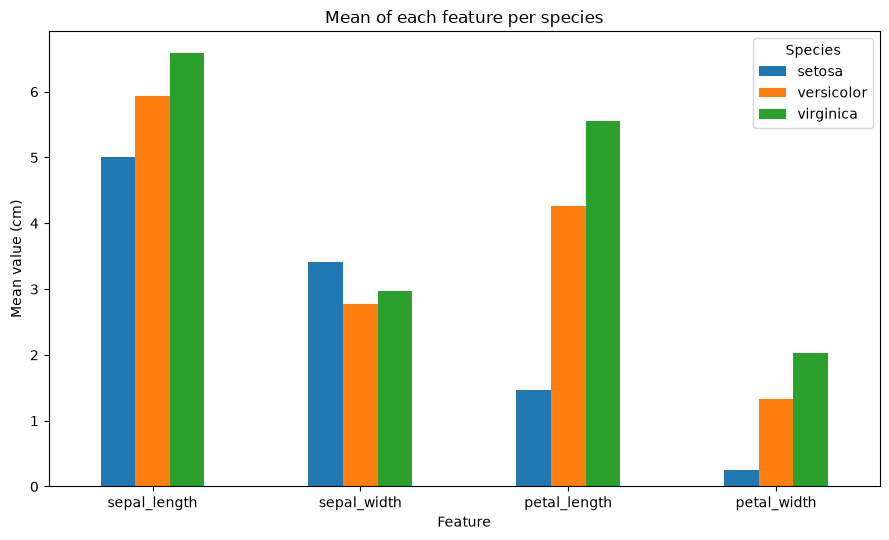

In [6]:
means = df.groupby("species")[features].mean()
print(means.round(2))

ax = means.T.plot(kind="bar", figsize=(9, 5.5), rot=0)
ax.set_title("Mean of each feature per species")
ax.set_xlabel("Feature")
ax.set_ylabel("Mean value (cm)")
ax.legend(title="Species")
plt.tight_layout()
plt.savefig(FIG_DIR / "exp02_feature_means.png", dpi=150)
plt.show()

## 6. Pair plot of all features

The pair plot draws every feature against every other feature, with the diagonal showing per-species distributions.

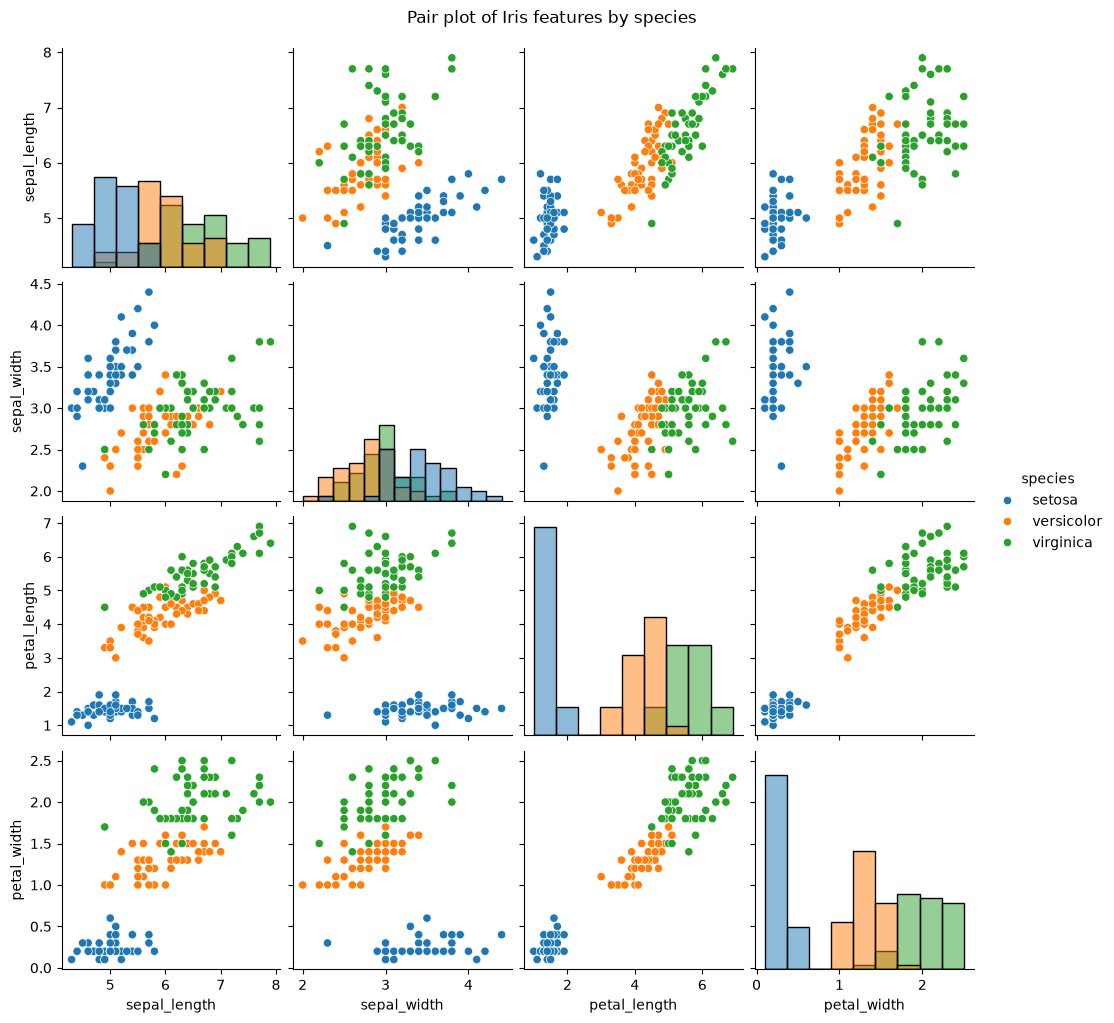

In [7]:
grid = sns.pairplot(df, hue="species", diag_kind="hist")
grid.fig.suptitle("Pair plot of Iris features by species", y=1.02)
grid.savefig(FIG_DIR / "exp02_pairplot.png", dpi=150)
plt.show()

## Observation

Based on the run above:

1. **Petal measurements separate the species best.** In the scatter plot, setosa is completely isolated (setosa petal length ≤ 1.9 cm vs ≥ 3.0 cm for the others; petal width ≤ 0.6 cm vs ≥ 1.0 cm), while versicolor and virginica partially overlap (petal length ranges cross between 4.5 and 5.1 cm).
2. The **histograms** confirm this: sepal width looks roughly bell-shaped, but petal length and petal width are bimodal — one hump for setosa and one shared by the other two species.
3. The **box plots** show virginica has the largest and most spread-out petals, setosa the smallest, and sepal width is the only feature whose species means barely differ (3.42 / 2.77 / 2.97 cm) — the weakest discriminator of the four.
4. The **bar chart of per-species means** and the **pair plot** tell the same story: any chart that puts petal length against petal width separates the classes almost perfectly, which is why those two features would be the first choice for a classifier.
5. The dataset is balanced (50 flowers per species), so no class-imbalance caveats apply.

## Result

The executed cells above provide the measured result for this experiment. The conclusion should be interpreted using the dataset and evaluation limits stated here.